# Diagnostic des maladies du manioc par classification d'images

**INF5101 — Traitement multimédia des données — TP image (slide 38)**

> - Construire une petite classification d'images avec transfer learning.
> - Comparer CNN simple, modèle pré-entraîné et augmentation de données.
> - Afficher la matrice de confusion et analyser les erreurs visuelles.
> - Bonus : tester une segmentation avec U-Net ou SAM.

Le manioc nourrit plus de 800 millions de personnes, dont une grande partie en Afrique
centrale, et ses principales maladies se reconnaissent sur les feuilles. Le jeu de données
*Cassava Leaf Disease Classification* (Makerere AI Lab, Ouganda) réunit 21 397 photos prises
**au champ, avec des téléphones** : arrière-plans encombrés, lumière variable, plusieurs
feuilles par image. Cinq classes :

| Code | Maladie | Symptôme typique |
|---|---|---|
| CBB | Bactériose (*Cassava Bacterial Blight*) | taches angulaires brunes, flétrissement |
| CBSD | Striure brune (*Cassava Brown Streak Disease*) | taches jaunes le long des nervures |
| CGM | Marbrure verte (*Cassava Green Mottle*) | motifs jaune-vert, feuilles déformées |
| CMD | Mosaïque (*Cassava Mosaic Disease*) | mosaïque jaune, feuilles tordues |
| Healthy | Feuille saine | — |

**Démarche.** Trois modèles, évalués sur le même jeu de test :

1. un **CNN simple** entraîné de zéro ;
2. le même CNN avec **augmentation de données** ;
3. un modèle **pré-entraîné** sur ImageNet (EfficientNetB0) adapté par **transfer learning**.

Puis matrices de confusion, analyse des erreurs, et en bonus une segmentation avec **SAM**.
Le notebook s'exécute sur Kaggle (GPU T4 gratuit, données hébergées sur place).

## Architecture

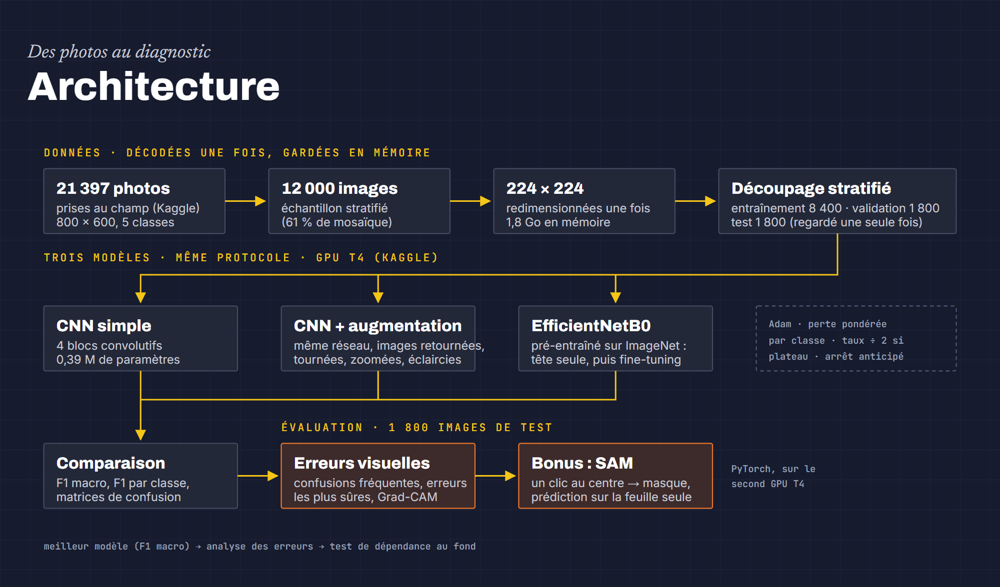

Les images sont décodées une seule fois puis gardées en mémoire ; les trois modèles suivent le même protocole d'entraînement sur le même découpage, et sont comparés sur le même jeu de test. Le meilleur sert ensuite à l'analyse des erreurs et au test SAM.

In [1]:
import time
from pathlib import Path

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

FAST = False  # True : 1 200 images et 1 époque, juste pour vérifier que tout tourne

SEED = 42
IMG_SIZE = 224
N_SAMPLE = 1_200 if FAST else 12_000
EPOCHS = 1 if FAST else None

IS_KAGGLE = Path("/kaggle/input").exists()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path("/kaggle/input/competitions/cassava-leaf-disease-classification") if IS_KAGGLE else ROOT / "data" / "cassava"
OUT = Path("/kaggle/working") if IS_KAGGLE else ROOT / "outputs"
OUT.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)

# un seul des deux GPU de Kaggle pour TensorFlow (l'autre servira à SAM), sans prendre toute sa mémoire
gpus = tf.config.list_physical_devices("GPU")
tf.config.set_visible_devices(gpus[:1], "GPU")
for gpu in gpus[:1]:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow {tf.__version__}, Keras {keras.__version__}, GPU : {len(gpus)}, FAST={FAST}")

TensorFlow 2.20.0, Keras 3.13.2, GPU : 2, FAST=False


## 1. Les données

### 1.1 Un jeu très déséquilibré

In [2]:
CLASSES = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
CLASS_NAMES_FR = ["Bactériose", "Striure brune", "Marbrure verte", "Mosaïque", "Saine"]
LABELS = list(range(len(CLASSES)))

full = pd.read_csv(DATA / "train.csv")
counts = full["label"].value_counts().sort_index()
pd.DataFrame({"classe": CLASSES, "nom": CLASS_NAMES_FR, "images": counts.values,
              "part": (counts / counts.sum()).round(3).values})

,classe,nom,images,part
0,CBB,Bactériose,1087,0.051
1,CBSD,Striure brune,2189,0.102
2,CGM,Marbrure verte,2386,0.112
3,CMD,Mosaïque,13158,0.615
4,Healthy,Saine,2577,0.120


La mosaïque (CMD) représente 61 % des images, la bactériose 5 %. Deux conséquences :

- l'**exactitude** (*accuracy*) est trompeuse : répondre toujours « mosaïque » donne déjà 61 %.
  On retient le **F1 macro**, la moyenne des F1 de chaque classe, où chaque maladie compte
  autant ;
- à l'entraînement, on **pondère la perte** par classe (`class_weight="balanced"`) : une erreur
  sur une bactériose coûte plus cher qu'une erreur sur une mosaïque.

### 1.2 Échantillon et découpage

On prend **12 000 images** au hasard en respectant les proportions (les trois entraînements
tiennent alors en un peu plus d'une heure sur un T4), découpées en 70 % d'entraînement, 15 % de validation (pour
arrêter l'entraînement au bon moment) et 15 % de test, qu'on ne regarde qu'à la fin.

In [3]:
sample, _ = train_test_split(full, train_size=N_SAMPLE, stratify=full["label"], random_state=SEED)
train_df, rest = train_test_split(sample, test_size=0.30, stratify=sample["label"], random_state=SEED)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=rest["label"], random_state=SEED)

split = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
split.to_csv(OUT / "split.csv", index=False)
pd.crosstab(split["label"].map(dict(enumerate(CLASSES))), split["split"], margins=True)

split,test,train,val,All
label,,,,
CBB,92,427,91,610
CBSD,184,860,184,1228
CGM,200,937,201,1338
CMD,1107,5165,1107,7379
Healthy,217,1011,217,1445
All,1800,8400,1800,12000


### 1.3 Chargement en mémoire

Les photos font 800 × 600 pixels. On les décode **une seule fois**, réduites en 224 × 224 (la
taille d'entrée d'EfficientNetB0), et on les garde en mémoire (≈ 1,8 Go) : les redécoder à
chaque époque ferait attendre le GPU.

In [4]:
def decode(path):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), antialias=True)
    return tf.cast(tf.round(image), tf.uint8)


def load_images(image_ids):
    paths = [str(DATA / "train_images" / image_id) for image_id in image_ids]
    dataset = tf.data.Dataset.from_tensor_slices(paths).map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    batches = list(dataset.batch(256).as_numpy_iterator())
    return np.concatenate(batches)


start = time.time()
X_train = load_images(train_df["image_id"])
X_val = load_images(val_df["image_id"])
X_test = load_images(test_df["image_id"])
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()
print(f"{len(X_train) + len(X_val) + len(X_test)} images chargées en {time.time() - start:.0f} s")

I0000 00:00:1793090811.686230      18 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


12000 images chargées en 50 s


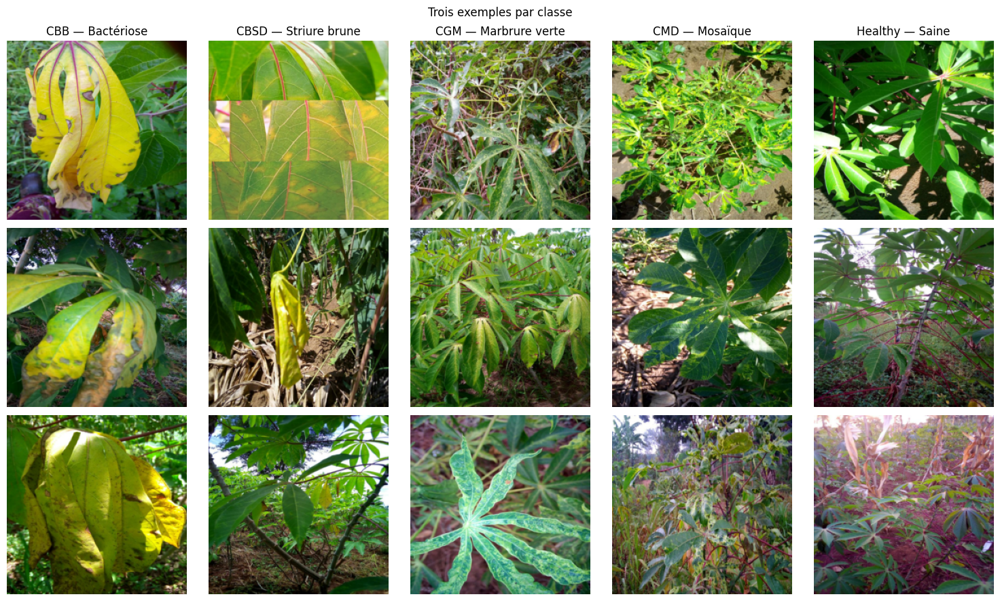

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for label in LABELS:
    for row, index in enumerate(np.flatnonzero(y_train == label)[:3]):
        axes[row, label].imshow(X_train[index])
        axes[row, label].axis("off")
    axes[0, label].set_title(f"{CLASSES[label]} — {CLASS_NAMES_FR[label]}")
plt.suptitle("Trois exemples par classe")
plt.tight_layout()
plt.show()

Les photos montrent la difficulté : arrière-plans chargés (sol, autres plantes, mains),
plusieurs feuilles par image, symptômes parfois minuscules. Les organisateurs de la compétition
signalent aussi qu'une partie des images porte une **mauvaise étiquette** : aucun modèle ne
peut atteindre 100 %.

## 2. Protocole commun d'entraînement

Les trois modèles sont entraînés de la même manière, pour que les écarts viennent du modèle et
non du protocole : optimiseur Adam, entropie croisée pondérée par classe, **taux
d'apprentissage divisé par deux** quand le F1 de validation stagne 3 époques (des pas plus
petits stabilisent la fin de l'entraînement), et **arrêt anticipé** : on s'arrête quand le F1 macro de validation ne progresse plus depuis quelques
époques, et on garde les poids de la meilleure époque.

In [6]:
CLASS_WEIGHT = dict(enumerate(compute_class_weight("balanced", classes=np.array(LABELS), y=y_train)))
print("poids des classes :", {CLASSES[k]: round(v, 2) for k, v in CLASS_WEIGHT.items()})


def make_dataset(X, y, training: bool) -> tf.data.Dataset:
    dataset = tf.data.Dataset.from_tensor_slices((X, keras.utils.to_categorical(y, len(CLASSES))))
    if training:
        dataset = dataset.shuffle(len(X), seed=SEED)
    return dataset.batch(32).prefetch(tf.data.AUTOTUNE)


val_ds = make_dataset(X_val, y_val, training=False)


def fit(model, epochs: int, learning_rate: float, patience: int = 5) -> dict:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1")],
    )
    callbacks = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_f1", mode="max", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=patience, restore_best_weights=True),
    ]
    history = model.fit(make_dataset(X_train, y_train, training=True), validation_data=val_ds,
                        epochs=EPOCHS or epochs, class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=2)
    return history.history


histories, train_times = {}, {}

poids des classes : {'CBB': np.float64(3.93), 'CBSD': np.float64(1.95), 'CGM': np.float64(1.79), 'CMD': np.float64(0.33), 'Healthy': np.float64(1.66)}


## 3. CNN simple, entraîné de zéro

Quatre blocs convolution 3 × 3 → normalisation par lot → ReLU → *max pooling* : à chaque bloc
le nombre de filtres double (32 → 256) et la résolution est divisée par deux. Un *global
average pooling* résume ensuite chaque carte par sa moyenne avant la couche de décision, ce
qui évite une énorme couche dense et rend le réseau indifférent à la position du symptôme.

In [7]:
def make_augmentation():
    # une feuille retournée ou tournée reste malade, et la lumière change d'une photo à l'autre
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.2),
        layers.RandomContrast(0.2, value_range=(0, 255)),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ], name="augmentation")


def simple_cnn(augment):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs) if augment else inputs
    x = layers.Rescaling(1 / 255)(x)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x)  # 0,99 par défaut : trop lent avec peu de pas par époque
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs)


cnn = simple_cnn(augment=False)
print(f"{cnn.count_params():,} paramètres")
start = time.time()
histories["CNN simple"] = fit(cnn, epochs=50, learning_rate=1e-3, patience=10)
train_times["CNN simple"] = time.time() - start

391,141 paramètres
Epoch 1/50


I0000 00:00:1793090879.673271      61 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


263/263 - 34s - 129ms/step - accuracy: 0.3405 - f1: 0.2543 - loss: 1.6275 - val_accuracy: 0.0556 - val_f1: 0.0341 - val_loss: 3.0636 - learning_rate: 0.0010
Epoch 2/50
263/263 - 17s - 63ms/step - accuracy: 0.4252 - f1: 0.3183 - loss: 1.4498 - val_accuracy: 0.4150 - val_f1: 0.3182 - val_loss: 1.4258 - learning_rate: 0.0010
Epoch 3/50
263/263 - 17s - 64ms/step - accuracy: 0.4733 - f1: 0.3526 - loss: 1.3879 - val_accuracy: 0.4339 - val_f1: 0.3297 - val_loss: 1.3520 - learning_rate: 0.0010
Epoch 4/50
263/263 - 17s - 64ms/step - accuracy: 0.5125 - f1: 0.4013 - loss: 1.2935 - val_accuracy: 0.3511 - val_f1: 0.2170 - val_loss: 1.7291 - learning_rate: 0.0010
Epoch 5/50
263/263 - 17s - 64ms/step - accuracy: 0.5290 - f1: 0.4130 - loss: 1.2600 - val_accuracy: 0.3944 - val_f1: 0.3684 - val_loss: 1.3983 - learning_rate: 0.0010
Epoch 6/50
263/263 - 17s - 64ms/step - accuracy: 0.5521 - f1: 0.4372 - loss: 1.2079 - val_accuracy: 0.2333 - val_f1: 0.2270 - val_loss: 1.8354 - learning_rate: 0.0010
Epoch 7/

## 4. Le même CNN avec augmentation de données

Avec 8 400 images d'entraînement, le réseau finit par apprendre les images par cœur plutôt que
les symptômes (**surapprentissage**) : le score d'entraînement monte, celui de validation
stagne. L'**augmentation** montre à chaque époque une version différente de chaque image
(retournée, tournée, zoomée, éclaircie), ce qui multiplie artificiellement les exemples. Les
couches d'augmentation ne s'activent qu'à l'entraînement : en prédiction, l'image est intacte.

In [8]:
cnn_aug = simple_cnn(augment=True)
start = time.time()
histories["CNN + augmentation"] = fit(cnn_aug, epochs=60, learning_rate=1e-3, patience=10)
train_times["CNN + augmentation"] = time.time() - start

Epoch 1/60
263/263 - 42s - 159ms/step - accuracy: 0.3199 - f1: 0.2405 - loss: 1.6579 - val_accuracy: 0.1644 - val_f1: 0.1227 - val_loss: 1.7708 - learning_rate: 0.0010
Epoch 2/60
263/263 - 33s - 126ms/step - accuracy: 0.4023 - f1: 0.2995 - loss: 1.5100 - val_accuracy: 0.5039 - val_f1: 0.2940 - val_loss: 1.3082 - learning_rate: 0.0010
Epoch 3/60
263/263 - 33s - 125ms/step - accuracy: 0.4277 - f1: 0.3139 - loss: 1.4568 - val_accuracy: 0.4094 - val_f1: 0.3176 - val_loss: 1.3755 - learning_rate: 0.0010
Epoch 4/60
263/263 - 33s - 125ms/step - accuracy: 0.4725 - f1: 0.3565 - loss: 1.3954 - val_accuracy: 0.2722 - val_f1: 0.2396 - val_loss: 1.7164 - learning_rate: 0.0010
Epoch 5/60
263/263 - 33s - 125ms/step - accuracy: 0.4869 - f1: 0.3760 - loss: 1.3435 - val_accuracy: 0.2583 - val_f1: 0.2427 - val_loss: 1.5900 - learning_rate: 0.0010
Epoch 6/60
263/263 - 33s - 125ms/step - accuracy: 0.5056 - f1: 0.3895 - loss: 1.3206 - val_accuracy: 0.3822 - val_f1: 0.3121 - val_loss: 1.5356 - learning_rate:

## 5. Transfer learning : EfficientNetB0 pré-entraîné sur ImageNet

Plutôt que d'apprendre à voir à partir de 8 400 photos, on part d'un réseau qui a déjà appris
sur 1,3 million d'images d'ImageNet : ses couches savent détecter contours, textures et
motifs, et tout cela se réutilise. **EfficientNetB0** (4 M de paramètres) est un bon
compromis entre précision et taille.

Deux temps, comme le recommande la documentation Keras :

1. **la tête seule** : le réseau pré-entraîné est gelé, on n'entraîne que la nouvelle couche
   de décision (5 classes). Sans cette étape, les gradients d'une tête initialisée au hasard
   abîmeraient les poids pré-entraînés dès les premiers pas ;
2. **fine-tuning** : on dégèle tout et on continue avec un taux d'apprentissage dix fois plus
   petit, pour ajuster finement les filtres aux feuilles de manioc. Les couches de
   normalisation par lot restent en mode inférence (`training=False`) pour garder leurs
   statistiques ImageNet.

On garde l'augmentation : avec 4 M de paramètres, ce réseau a largement de quoi apprendre par cœur 8 400 images, et c'est contre ce risque que l'augmentation est utile.

In [9]:
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
features = base(make_augmentation()(inputs), training=False)  # pixels entre 0 et 255 : EfficientNet normalise lui-même
x = layers.GlobalAveragePooling2D()(features)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax", name="probs")(x)
effnet = keras.Model(inputs, outputs)

start = time.time()
head = fit(effnet, epochs=5, learning_rate=1e-3)  # 1. la tête seule
head_epochs = len(head["f1"])
base.trainable = True
finetune = fit(effnet, epochs=20, learning_rate=1e-4, patience=6)  # 2. tout le réseau
train_times["EfficientNetB0 (transfert)"] = time.time() - start

history = {}
for key in head:
    history[key] = head[key] + finetune[key]
histories["EfficientNetB0 (transfert)"] = history
print(f"{effnet.count_params():,} paramètres")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5


E0000 00:00:1793093225.454562      18 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_4_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


263/263 - 36s - 138ms/step - accuracy: 0.4987 - f1: 0.3711 - loss: 1.3454 - val_accuracy: 0.5789 - val_f1: 0.4646 - val_loss: 1.1883 - learning_rate: 0.0010
Epoch 2/5
263/263 - 22s - 85ms/step - accuracy: 0.5906 - f1: 0.4678 - loss: 1.1839 - val_accuracy: 0.6078 - val_f1: 0.5103 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 3/5
263/263 - 23s - 86ms/step - accuracy: 0.6130 - f1: 0.4874 - loss: 1.1363 - val_accuracy: 0.6200 - val_f1: 0.5165 - val_loss: 1.0686 - learning_rate: 0.0010
Epoch 4/5
263/263 - 22s - 85ms/step - accuracy: 0.6154 - f1: 0.4941 - loss: 1.1220 - val_accuracy: 0.6094 - val_f1: 0.5140 - val_loss: 1.1401 - learning_rate: 0.0010
Epoch 5/5
263/263 - 22s - 85ms/step - accuracy: 0.6244 - f1: 0.5071 - loss: 1.1041 - val_accuracy: 0.6328 - val_f1: 0.5243 - val_loss: 1.0419 - learning_rate: 0.0010
Epoch 1/20


E0000 00:00:1793093375.992667      18 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_4_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


263/263 - 126s - 477ms/step - accuracy: 0.5176 - f1: 0.4215 - loss: 1.2126 - val_accuracy: 0.5956 - val_f1: 0.5246 - val_loss: 1.0931 - learning_rate: 1.0000e-04
Epoch 2/20
263/263 - 89s - 338ms/step - accuracy: 0.6717 - f1: 0.5624 - loss: 0.9451 - val_accuracy: 0.5644 - val_f1: 0.5132 - val_loss: 1.2168 - learning_rate: 1.0000e-04
Epoch 3/20
263/263 - 89s - 339ms/step - accuracy: 0.7140 - f1: 0.6117 - loss: 0.8524 - val_accuracy: 0.5844 - val_f1: 0.5267 - val_loss: 1.0790 - learning_rate: 1.0000e-04
Epoch 4/20
263/263 - 89s - 339ms/step - accuracy: 0.7412 - f1: 0.6403 - loss: 0.7692 - val_accuracy: 0.6689 - val_f1: 0.5982 - val_loss: 0.9057 - learning_rate: 1.0000e-04
Epoch 5/20
263/263 - 89s - 339ms/step - accuracy: 0.7588 - f1: 0.6682 - loss: 0.7144 - val_accuracy: 0.7006 - val_f1: 0.6143 - val_loss: 0.8271 - learning_rate: 1.0000e-04
Epoch 6/20
263/263 - 89s - 339ms/step - accuracy: 0.7760 - f1: 0.6890 - loss: 0.6709 - val_accuracy: 0.6483 - val_f1: 0.5954 - val_loss: 0.9553 - lear

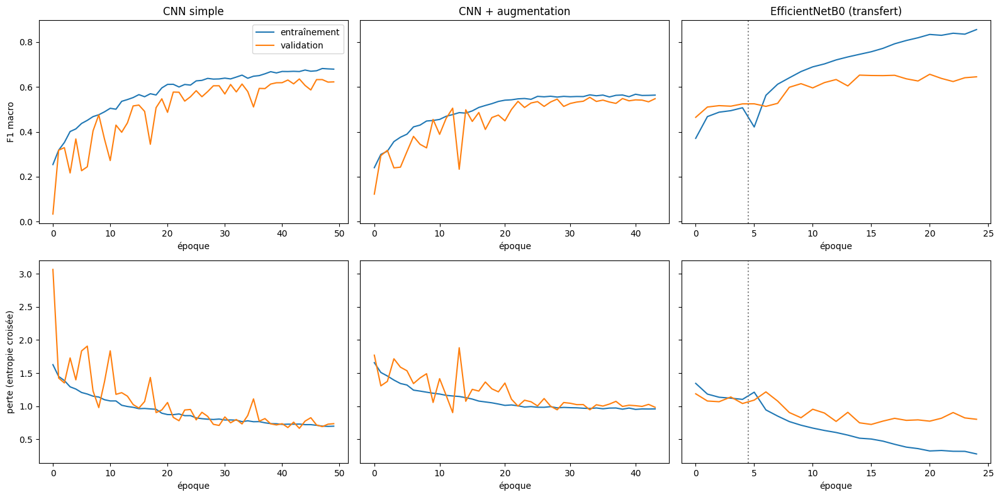

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey="row")
for col, (name, history) in enumerate(histories.items()):
    for row, metric in enumerate(["f1", "loss"]):
        axes[row, col].plot(history[metric], label="entraînement")
        axes[row, col].plot(history[f"val_{metric}"], label="validation")
        axes[row, col].set_xlabel("époque")
    axes[0, col].set_title(name)
axes[0, 0].set_ylabel("F1 macro")
axes[1, 0].set_ylabel("perte (entropie croisée)")
axes[0, 0].legend()
for ax in axes[:, 2]:
    ax.axvline(head_epochs - 0.5, color="grey", linestyle=":")
plt.tight_layout()
plt.savefig(OUT / "courbes_apprentissage.png", dpi=120)
plt.show()

En haut le F1 macro, en bas la perte. Un écart qui se creuse entre entraînement et
validation signe le surapprentissage ; deux courbes basses et proches, le sous-apprentissage.
Sur les courbes du transfert, la ligne pointillée marque le passage au fine-tuning.

## 6. Comparaison sur le jeu de test

In [11]:
models = {"CNN simple": cnn, "CNN + augmentation": cnn_aug, "EfficientNetB0 (transfert)": effnet}

test_probs = {}
test_pred = {}
for name, model in models.items():
    test_probs[name] = model.predict(X_test, batch_size=64, verbose=0)
    test_pred[name] = test_probs[name].argmax(1)

table = {}
for name, pred in test_pred.items():
    row = {
        "paramètres": f"{models[name].count_params():,}",
        "entraînement (min)": round(train_times[name] / 60, 1),
        "exactitude": round(accuracy_score(y_test, pred), 3),
        "F1 macro": round(f1_score(y_test, pred, average="macro"), 3),
    }
    f1_per_class = f1_score(y_test, pred, labels=LABELS, average=None).round(3)
    for class_name, score in zip(CLASSES, f1_per_class):
        row[f"F1 {class_name}"] = score
    table[name] = row

pd.DataFrame(table).T

,paramètres,entraînement (min),exactitude,F1 macro,F1 CBB,F1 CBSD,F1 CGM,F1 CMD,F1 Healthy
CNN simple,"391,141",14.8,0.77,0.635,0.474,0.647,0.569,0.906,0.581
CNN + augmentation,"391,141",24.3,0.643,0.54,0.433,0.553,0.449,0.793,0.471
EfficientNetB0 (transfert),"4,055,976",32.5,0.745,0.64,0.565,0.605,0.573,0.874,0.583


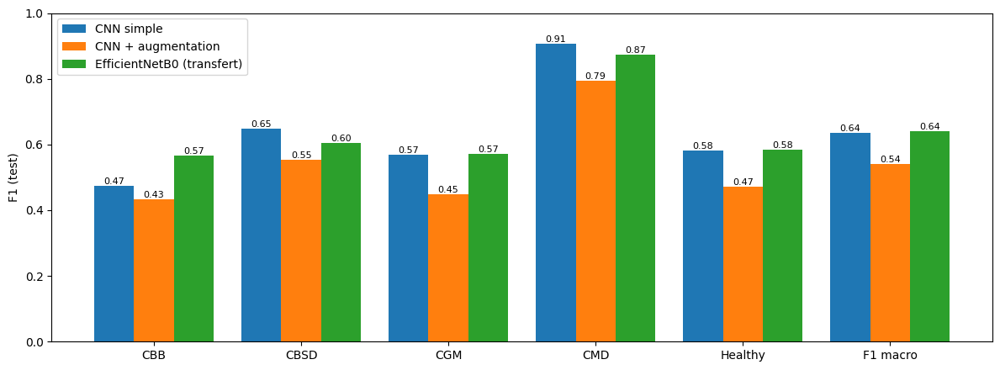

In [12]:
groups = CLASSES + ["F1 macro"]
positions = np.arange(len(groups))
width = 0.27

fig, ax = plt.subplots(figsize=(12, 4.5))
for k, (name, pred) in enumerate(test_pred.items()):
    scores = list(f1_score(y_test, pred, labels=LABELS, average=None))
    scores.append(f1_score(y_test, pred, average="macro"))
    bars = ax.bar(positions + (k - 1) * width, scores, width, label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(positions, groups)
ax.set_ylabel("F1 (test)")
ax.set_ylim(0, 1)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(OUT / "comparaison_f1.png", dpi=120)
plt.show()

### Matrices de confusion

Normalisées par ligne : la diagonale donne le **rappel** de chaque classe (la part des vraies
feuilles de cette classe retrouvées), une case hors diagonale la part d'une classe prise pour
une autre.

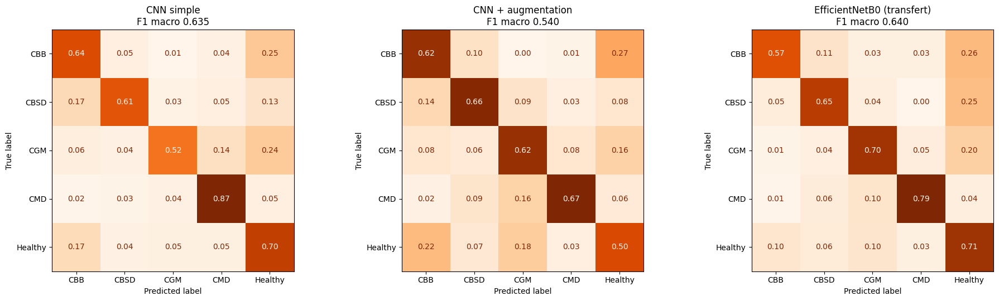

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (name, pred) in zip(axes, test_pred.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, display_labels=CLASSES, normalize="true",
                                            values_format=".2f", cmap="Oranges", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nF1 macro {f1_score(y_test, pred, average='macro'):.3f}")
plt.tight_layout()
plt.savefig(OUT / "matrices_confusion.png", dpi=120)
plt.show()

In [14]:
print(classification_report(y_test, test_pred["EfficientNetB0 (transfert)"], labels=LABELS,
                            target_names=CLASSES, digits=3, zero_division=0))

              precision    recall  f1-score   support

         CBB      0.565     0.565     0.565        92
        CBSD      0.563     0.652     0.605       184
         CGM      0.484     0.700     0.573       200
         CMD      0.978     0.790     0.874      1107
     Healthy      0.495     0.710     0.583       217

    accuracy                          0.745      1800
   macro avg      0.617     0.683     0.640      1800
weighted avg      0.801     0.745     0.762      1800



## 7. Analyse des erreurs visuelles du meilleur modèle

### 7.1 Les confusions les plus fréquentes

In [15]:
best_probs = test_probs["EfficientNetB0 (transfert)"]
best_pred = best_probs.argmax(1)
confidence = best_probs.max(1)
names = np.array(CLASSES)
errors = pd.DataFrame({"vrai": names[y_test], "prédit": names[best_pred]})[best_pred != y_test]
print(f"{len(errors)} erreurs sur {len(y_test)} images de test")
errors.value_counts().head(8).rename("erreurs").to_frame()

459 erreurs sur 1800 images de test


erreurs
vrai    prédit          
CMD     CGM          116
        CBSD          62
        Healthy       48
CBSD    Healthy       46
CGM     Healthy       39
CBB     Healthy       24
Healthy CGM           22
        CBB           21

### 7.2 Ce que regarde le réseau : Grad-CAM

**Grad-CAM** colore les zones de l'image qui ont le plus pesé dans la décision. Ici la dernière
couche convolutive d'EfficientNet (7 × 7 × 1 280) est suivie d'une simple moyenne puis de la
couche de décision : Grad-CAM revient alors à pondérer chaque carte par le poids qui la relie
à la classe prédite, $\text{CAM}_c(i,j) = \sum_k w_{k,c} A_k(i,j)$ (Zhou et al., 2016).

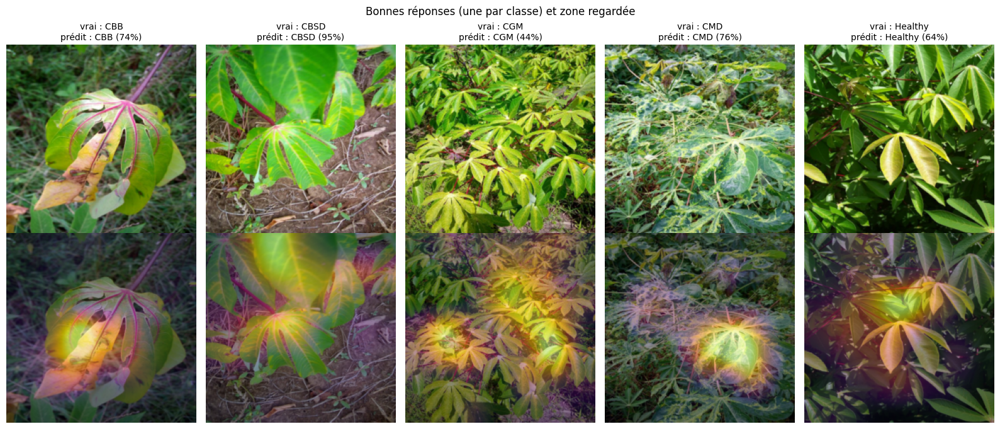

In [16]:
feature_model = keras.Model(effnet.input, features)
class_weights_dense = effnet.get_layer("probs").get_weights()[0]


def heatmap(image, label):
    feature_map = feature_model.predict(image[None], verbose=0)[0]
    cam = np.maximum(feature_map @ class_weights_dense[:, label], 0)
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    colored = plt.cm.inferno(np.clip(cam, 0, 1))[..., :3] * 255
    return (0.55 * image + 0.45 * colored).astype(np.uint8)


def show_cases(indices, title):
    fig, axes = plt.subplots(2, len(indices), figsize=(3.2 * len(indices), 7), squeeze=False)
    for col, index in enumerate(indices):
        pred = best_pred[index]
        axes[0, col].imshow(X_test[index])
        axes[0, col].set_title(f"vrai : {CLASSES[y_test[index]]}\nprédit : {CLASSES[pred]} ({confidence[index]:.0%})",
                               fontsize=10)
        axes[1, col].imshow(heatmap(X_test[index], pred))
        for ax in axes[:, col]:
            ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


correct = np.flatnonzero(best_pred == y_test)
examples = []
for label in LABELS:
    correct_of_class = correct[y_test[correct] == label]
    if len(correct_of_class) > 0:
        examples.append(correct_of_class[0])
show_cases(examples, "Bonnes réponses (une par classe) et zone regardée")

### 7.3 Les erreurs les plus sûres d'elles

Les erreurs commises avec une forte confiance sont les plus instructives. On y cherche trois
familles : **étiquette douteuse** (l'image ressemble vraiment à ce que prédit le modèle),
**symptôme minuscule ou hors champ**, et **raccourci** (le réseau regarde le sol ou une autre
plante plutôt que la feuille).

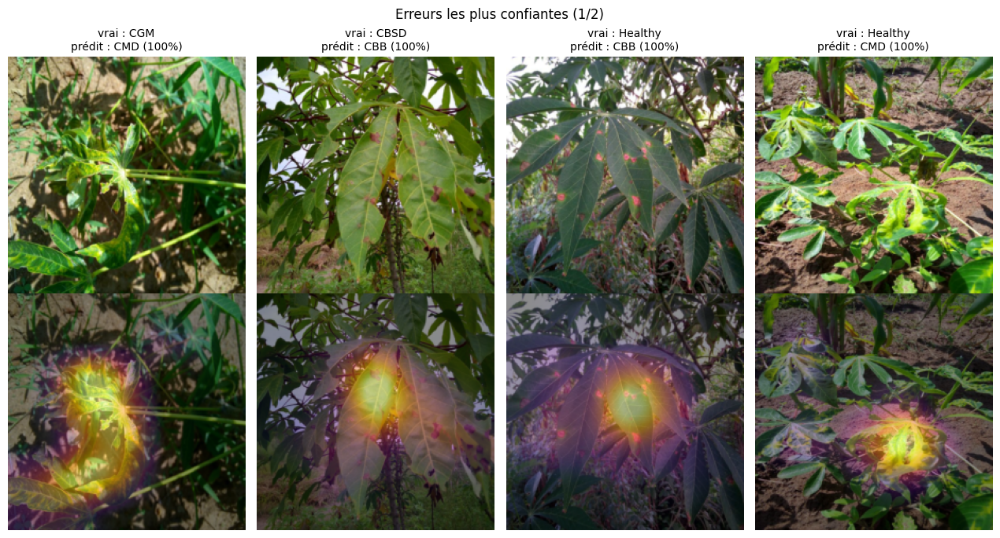

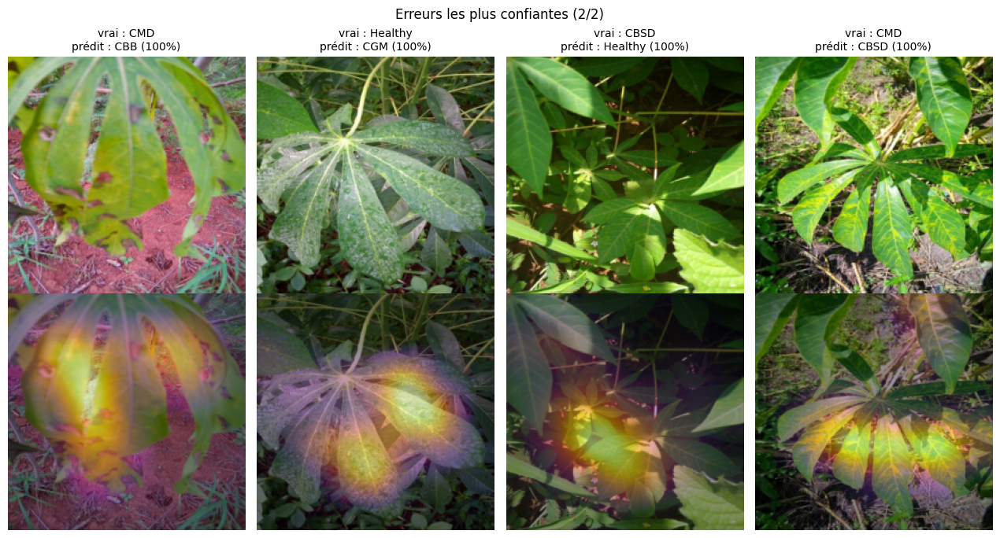

In [17]:
wrong = np.flatnonzero(best_pred != y_test)
most_confident_errors = wrong[np.argsort(-confidence[wrong])][:8]
show_cases(most_confident_errors[:4], "Erreurs les plus confiantes (1/2)")
show_cases(most_confident_errors[4:], "Erreurs les plus confiantes (2/2)")

## 8. Bonus : segmentation de la feuille avec SAM

**SAM** (*Segment Anything*, Meta, 2023) segmente n'importe quel objet à partir d'un simple
clic, sans entraînement spécifique. On lui donne le centre de l'image (là où se trouve en
général la feuille photographiée) et il renvoie le masque de l'objet.

On s'en sert pour une question précise : **le modèle s'appuie-t-il sur l'arrière-plan ?** On
détoure la feuille de 300 images de test, on remplace le fond par du gris, et on compare les
prédictions du modèle, sans le réentraîner. Si le score s'effondre, le modèle utilisait le
contexte (sol, plantes voisines) ; s'il tient, il regarde bien la feuille.

In [18]:
import torch
from PIL import Image
from transformers import SamModel, SamProcessor

TORCH_DEVICE = f"cuda:{torch.cuda.device_count() - 1}" if torch.cuda.is_available() else "cpu"
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(TORCH_DEVICE).eval()
sam_processor = SamProcessor.from_pretrained("facebook/sam-vit-base")


@torch.no_grad()
def leaf_mask(image_id: str) -> np.ndarray:
    image = Image.open(DATA / "train_images" / image_id).convert("RGB")
    inputs = sam_processor(image, input_points=[[[image.width / 2, image.height / 2]]],
                           return_tensors="pt").to(TORCH_DEVICE)
    outputs = sam(**inputs)
    masks = sam_processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0][0]
    # SAM propose trois masques (partie, objet, ensemble) : on garde celui qu'il juge le meilleur.
    best = masks[outputs.iou_scores[0, 0].argmax().item()].numpy().astype(np.uint8)
    return cv2.resize(best, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST).astype(bool)


n_sam = 60 if FAST else 300
masks = np.array([leaf_mask(image_id) for image_id in test_df["image_id"].iloc[:n_sam]])
X_masked = np.where(masks[..., None], X_test[:n_sam], 128).astype(np.uint8)
masked_pred = effnet.predict(X_masked, verbose=0).argmax(1)

pd.Series({
    "part de l'image occupée par la feuille": f"{masks.mean():.0%}",
    "F1 macro, image entière": round(f1_score(y_test[:n_sam], best_pred[:n_sam], average="macro"), 3),
    "F1 macro, feuille seule": round(f1_score(y_test[:n_sam], masked_pred, average="macro"), 3),
    "prédictions qui changent": f"{(masked_pred != best_pred[:n_sam]).mean():.0%}",
}).to_frame(f"{n_sam} images de test")

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

,300 images de test
part de l'image occupée par la feuille,9%
"F1 macro, image entière",0.701
"F1 macro, feuille seule",0.194
prédictions qui changent,54%


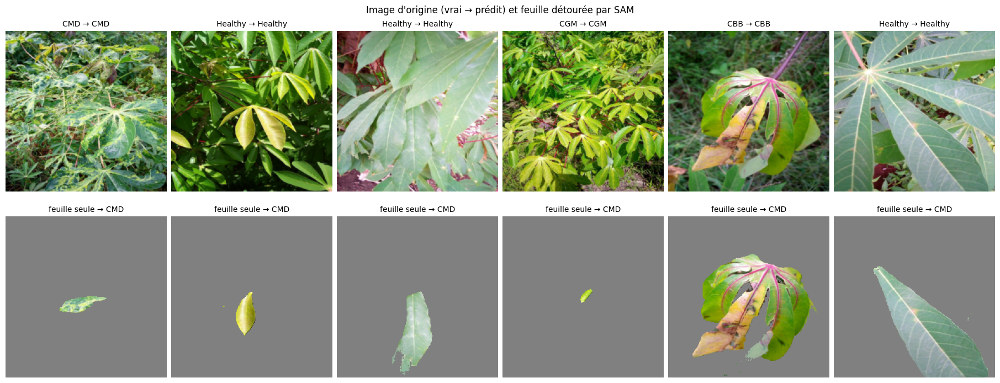

In [19]:
fig, axes = plt.subplots(2, 6, figsize=(18, 7), layout="constrained")
for col in range(6):
    axes[0, col].imshow(X_test[col])
    axes[0, col].set_title(f"{CLASSES[y_test[col]]} → {CLASSES[best_pred[col]]}", fontsize=10)
    axes[1, col].imshow(X_masked[col])
    axes[1, col].set_title(f"feuille seule → {CLASSES[masked_pred[col]]}", fontsize=10)
    for ax in axes[:, col]:
        ax.axis("off")
plt.suptitle("Image d'origine (vrai → prédit) et feuille détourée par SAM")
plt.savefig(OUT / "segmentation_sam.png", dpi=120)
plt.show()

## 9. Conclusions

**Résultats sur les 1 800 images de test** (8 400 images d'entraînement)

| Modèle | Paramètres | Entraînement | Exactitude | F1 macro |
|---|---|---|---|---|
| CNN simple | 0,39 M | 15 min | **0,770** | 0,635 |
| CNN + augmentation | 0,39 M | 24 min | 0,643 | 0,540 |
| EfficientNetB0 (transfert) | 4,1 M | 33 min | 0,745 | **0,640** |

**1. Le transfert et le CNN simple font jeu égal, et c'est instructif.** Avec 1 800 images de
test, 0,640 contre 0,635 de F1 macro n'est pas un écart significatif. Le transfert est
nettement meilleur sur la classe la plus rare (CBB 0,57 contre 0,47), le CNN simple sur la
mosaïque, très majoritaire (0,91 contre 0,87), d'où sa meilleure exactitude ; les autres
classes sont à égalité. Un
premier essai sur deux fois moins d'images (4 200 en entraînement) donnait 0,620 pour le
transfert contre 0,547 pour le CNN simple : **l'avantage du transfert est grand quand les
données sont rares, et fond quand elles abondent**. C'est exactement ce qu'on attend : les
filtres appris sur ImageNet remplacent les données qu'on n'a pas. Le CNN simple a d'ailleurs
atteint sa limite de 50 époques en progressant encore.

**2. Le transfert surapprend, le CNN augmenté sous-apprend : les courbes de perte le
montrent.**
- EfficientNetB0 : la perte d'entraînement descend à 0,3 pendant que celle de validation
  remonte vers 0,8 ; F1 de 0,85 en entraînement contre 0,65 en validation. Le modèle a de quoi
  apprendre par cœur, la validation plafonne dès la 14ᵉ époque.
- CNN + augmentation : les deux courbes restent collées et basses (F1 ≈ 0,55). Ce petit
  réseau n'a pas assez de capacité pour la tâche rendue plus difficile par l'augmentation.
  **L'augmentation soigne le surapprentissage ; appliquée à un modèle qui sous-apprend,
  elle aggrave le problème.** Le CNN simple, lui, ne surapprend presque pas (0,68 contre
  0,62) : il n'avait pas besoin d'augmentation.
- Le taux d'apprentissage divisé par deux quand la validation stagne (`ReduceLROnPlateau`) a
  supprimé les oscillations brutales des premiers essais : les courbes de validation sont
  maintenant lisses en fin d'entraînement.

**3. Les erreurs ont un sens visuel.**
- La confusion de loin la plus fréquente est **mosaïque → marbrure verte** (116 erreurs) :
  les deux maladies dessinent des motifs jaune-vert ; la mosaïque se distingue surtout par
  des feuilles plus tordues.
- Les feuilles malades prises pour **saines** forment la deuxième famille (CBSD, CGM, CBB →
  Healthy) : symptômes discrets ou feuille malade minoritaire dans la photo.
- Plusieurs erreurs « sûres à 100 % » ressemblent à des **erreurs d'étiquette** : une feuille
  étiquetée *saine* couverte de taches rouge-brun, prédite bactériose (CBB). Ce bruit
  d'étiquetage, signalé par les organisateurs, plafonne tous les scores.
- Grad-CAM montre que le réseau regarde **les feuilles et leurs taches**, pas le sol ni le
  ciel.

**4. Bonus SAM : la segmentation marche.** SAM détoure
proprement ce qu'on désigne, mais un clic au centre d'une photo de manioc désigne souvent
**une seule foliole** (9 % de l'image en moyenne). Sur la feuille seule, le modèle répond
presque toujours « mosaïque » et le F1 tombe de 0,70 à 0,19. Ce n'est pas la preuve qu'il
triche avec l'arrière-plan (Grad-CAM dit le contraire) : on lui a retiré l'essentiel des
symptômes, répartis sur toute la plante, et montré un fond gris jamais vu à l'entraînement.
Pour isoler la plante entière, il faudrait plusieurs clics ou une boîte englobante, ou un
U-Net entraîné sur des masques de feuilles, et réentraîner le classifieur sur ces images
détourées.

**Pour aller plus loin** : les 21 397 images, une plus haute résolution et un modèle plus
gros (EfficientNetB3), plus de régularisation pour le transfert (dropout plus fort, dégel
partiel des dernières couches seulement), et un déploiement dans une application de
diagnostic.